# 03 — Hypotheses, Regression and Diagnostics

The core of the project: nested OLS models of log salary, quadratic and interaction effects, the full battery of assumption checks, and robustness models.

**Design decisions worth flagging up front**

- The dependent variable is `log(sal)`. Salary in levels has a skewness of 5.4; the logarithm is close to symmetric, and coefficients then read as proportional effects.
- Continuous regressors that enter a square or an interaction are **mean-centred**. Without centring, `edu` and `edu²` have variance inflation factors above 80 purely from the arithmetic of the product. Centring removes that structural collinearity, and the linear coefficient then reads as the effect at the *average* level of that variable.
- Heteroskedasticity-robust HC3 standard errors are reported throughout, so inference does not depend on the normality of the errors.

> *One of three notebooks: `01_data_processing`, `02_eda_visualisations` and `03_hypothesis_regression`. Run them in order from the `notebooks/` directory.*

## Setup

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import jarque_bera

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CLEAN = ROOT / "ITEmp_Cleaned.csv"
COMPLETE = ROOT / "ITEmp_CompleteCase.csv"
TABLES = ROOT / "output_tables"
CHARTS = ROOT / "report_charts"

DV_LOG, DV_LVL = "log_sal", "sal"

# variables that appear in a square or an interaction -> centred
CENTER = ["edu", "exper", "ten", "dep", "momed", "daded", "sib"]

HC = "c_edu + c_exper + c_ten"
DEMO = "female + married + nonprev + c_dep"
GEO = "metro + norcen + south + west"
JOB = ("itreq + itprog + itqual + itarch + itrd + ittech + itai + itclient "
       "+ wrkhm")
FAM = "c_momed + c_daded + c_sib"
QUAD = "c_exper_sq + c_ten_sq + c_edu_sq"
INTER = "c_edu:female + c_exper:c_edu + married:female + metro:c_edu"

FORMULAS = {
    "M1 Human capital": f"{DV_LOG} ~ {HC}",
    "M2 + Demographics": f"{DV_LOG} ~ {HC} + {DEMO}",
    "M3 + Geography": f"{DV_LOG} ~ {HC} + {DEMO} + {GEO}",
    "M4 + Job function": f"{DV_LOG} ~ {HC} + {DEMO} + {GEO} + {JOB}",
    "M5 Full main effects": f"{DV_LOG} ~ {HC} + {DEMO} + {GEO} + {JOB} + {FAM}",
    "M6 + Quadratics": f"{DV_LOG} ~ {HC} + {DEMO} + {GEO} + {JOB} + {FAM} + {QUAD}",
    "M7 + Interactions": (f"{DV_LOG} ~ {HC} + {DEMO} + {GEO} + {JOB} + {FAM} "
                          f"+ {QUAD} + {INTER}"),
}
PREFERRED = "M7 + Interactions"

## helpers

Loading, the centring step, the model formulas, and the small utilities for significance stars and hypothesis verdicts.

The formulas are built from named blocks (human capital, demographics, geography, job function, family background, quadratics, interactions) so the nesting from M1 to M7 is explicit.

In [2]:
def load() -> pd.DataFrame:
    df = pd.read_csv(CLEAN)
    for v in CENTER:
        df[f"c_{v}"] = df[v] - df[v].mean()
    for v in ["exper", "ten", "edu"]:
        df[f"c_{v}_sq"] = df[f"c_{v}"] ** 2
    return df


def fit(formula: str, data: pd.DataFrame, cov: str | None = None):
    m = smf.ols(formula, data=data)
    return m.fit(cov_type=cov) if cov else m.fit()


def stars(p: float) -> str:
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def verdict(b: float, p: float, expected: str, alpha=.05, weak=.10) -> str:
    sign_ok = (b > 0) if expected == "+" else (b < 0) if expected == "-" else True
    if p < alpha and sign_ok:
        return "Supported"
    if p < alpha and not sign_ok:
        return "Significant, opposite sign"
    if p < weak and sign_ok:
        return "Weakly supported"
    return "Not supported"

## coefficient tables

Formats the fitted models into a stargazer-style table — coefficient with stars, standard error underneath — and writes both CSV and LaTeX.

In [3]:
def coef_table(models: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    index = list(dict.fromkeys(sum((list(m.params.index) for m in models.values()), [])))
    coef, se = {}, {}
    for label, res in models.items():
        coef[label] = {v: (f"{res.params[v]:.4f}{stars(res.pvalues[v])}"
                           if v in res.params.index else "") for v in index}
        se[label] = {v: (f"({res.bse[v]:.4f})" if v in res.params.index else "")
                     for v in index}
    return (pd.DataFrame(coef, index=index),
            pd.DataFrame(se, index=index))


def model_stats(models: dict) -> pd.DataFrame:
    rows = []
    for label, res in models.items():
        rows.append({"model": label, "k_params": int(res.df_model) + 1,
                     "n": int(res.nobs), "r_squared": res.rsquared,
                     "adj_r_squared": res.rsquared_adj, "aic": res.aic,
                     "bic": res.bic, "f_stat": float(res.fvalue),
                     "f_pvalue": float(res.f_pvalue)})
    return pd.DataFrame(rows).round(4)


def write_latex(coef_df, se_df, stats, path, caption, label):
    cols = list(coef_df.columns)
    n = len(cols)
    body = []
    for var in coef_df.index:
        var_tex = var.replace("_", r"\_").replace(":", r" $\times$ ")
        body.append(" & ".join([var_tex] + [str(coef_df.loc[var, c]) for c in cols]) + r" \\")
        body.append(" & ".join([""] + [str(se_df.loc[var, c]) for c in cols]) + r" \\")
    add = []
    for row_label, key, fmt in [("N", "n", "{:.0f}"),
                                ("R-squared", "r_squared", "{:.3f}"),
                                ("Adjusted R-squared", "adj_r_squared", "{:.3f}"),
                                ("AIC", "aic", "{:.1f}"), ("BIC", "bic", "{:.1f}")]:
        vals = [fmt.format(stats.loc[stats.model == c, key].iloc[0]) for c in cols]
        add.append(" & ".join([row_label] + vals) + r" \\")
    tex = "\n".join([r"\begin{table}[htbp]", r"\centering",
                     rf"\caption{{{caption}}}", rf"\label{{{label}}}",
                     r"\begin{tabular}{l" + "c" * n + "}", r"\hline\hline",
                     " & ".join([""] + cols) + r" \\", r"\hline",
                     *body, r"\hline", *add, r"\hline\hline", r"\end{tabular}",
                     r"\end{table}", "",
                     r"\textit{Notes: *** p<0.01, ** p<0.05, * p<0.10; standard errors in parentheses.}"])
    path.write_text(tex)

## diagnostics

The assumption checks, one function per concern:

- **Jarque–Bera** for residual normality.
- **Breusch–Pagan** and the **White/Wooldridge** test for heteroskedasticity.
- **Ramsey RESET**, in both its classical and its heteroskedasticity-robust (Thursby–Schmidt) form, for functional form.
- The **condition number** of the design matrix for collinearity, and **Cook's distance** for influence.
- A **partial-residual test**: for each continuous regressor, residualise both it and the outcome on all the other regressors, then test whether that regressor's square and cube add explanatory power. This isolates *which* variable, if any, is non-linear.

In [4]:
def robust_reset(res, power=2):
    """Thursby-Schmidt RESET: test fitted powers with HC3 covariance."""
    y = res.model.endog
    fitted = res.fittedvalues
    aug = np.column_stack([res.model.exog] + [fitted ** k for k in range(2, power + 1)])
    r = sm.OLS(y, aug).fit(cov_type="HC3")
    R = np.zeros((power - 1, aug.shape[1]))
    for i in range(power - 1):
        R[i, aug.shape[1] - (power - 1) + i] = 1
    w = r.wald_test(R)
    return float(np.squeeze(w.statistic)), float(np.squeeze(w.pvalue))


def white_test(res):
    """Wooldridge form of White's test: regress u^2 on yhat and yhat^2."""
    z = pd.DataFrame({"yhat": res.fittedvalues, "yhat2": res.fittedvalues ** 2})
    r = sm.OLS(res.resid ** 2, sm.add_constant(z)).fit()
    f = r.f_test("yhat = 0, yhat2 = 0")
    return float(np.squeeze(f.fvalue)), float(np.squeeze(f.pvalue))


def diagnostics(res, label: str) -> list[dict]:
    x, resid = res.model.exog, res.resid
    out = []

    jb, jb_p, _, _ = jarque_bera(resid)
    out.append({"model": label, "test": "Jarque-Bera (residual normality)",
                "statistic": jb, "p_value": jb_p,
                "conclusion": "residuals normal" if jb_p > .05 else "residuals non-normal"})

    bp = het_breuschpagan(resid, x)
    out.append({"model": label, "test": "Breusch-Pagan (heteroskedasticity)",
                "statistic": bp[0], "p_value": bp[1],
                "conclusion": "homoskedastic" if bp[1] > .05 else "heteroskedastic"})

    w, wp = white_test(res)
    out.append({"model": label, "test": "White / Wooldridge (heteroskedasticity)",
                "statistic": w, "p_value": wp,
                "conclusion": "homoskedastic" if wp > .05 else "heteroskedastic"})

    r = linear_reset(res, power=2, use_f=True)
    out.append({"model": label, "test": "Ramsey RESET (functional form)",
                "statistic": float(r.fvalue), "p_value": float(r.pvalue),
                "conclusion": "correctly specified" if r.pvalue > .05
                              else "misspecified"})

    rs, rp = robust_reset(res)
    out.append({"model": label, "test": "RESET, HC3-robust",
                "statistic": rs, "p_value": rp,
                "conclusion": "correctly specified" if rp > .05 else "misspecified"})

    cn = float(np.linalg.cond(x))
    out.append({"model": label, "test": "Condition number of X",
                "statistic": cn, "p_value": np.nan,
                "conclusion": "acceptable" if cn < 30 else
                              "elevated, but scale-sensitive: see VIF table"})

    cooks = res.get_influence().cooks_distance[0]
    share = float((cooks > 4 / res.nobs).mean())
    out.append({"model": label, "test": "Cook's D: share > 4/n (max D)",
                "statistic": share, "p_value": np.nan,
                "conclusion": (f"max D = {cooks.max():.3f}; no dominating "
                               "observation") if cooks.max() < 1
                              else "an observation is highly influential"})
    return out


def vif_table(res) -> pd.DataFrame:
    x, names = res.model.exog, res.model.exog_names
    df = pd.DataFrame({"variable": names,
                       "VIF": [variance_inflation_factor(x, i) for i in range(x.shape[1])]})
    df = df[df.variable != "Intercept"].copy()
    df["tolerance"] = 1 / df["VIF"]
    df["flag"] = np.where(df.VIF > 10, "severe (>10)",
                          np.where(df.VIF > 5, "moderate (>5)", "ok"))
    return df.sort_values("VIF", ascending=False).round(3)


def partial_residual_tests(res) -> pd.DataFrame:
    """Test for unmodelled curvature in each continuous regressor.

    For regressor j, residualise y and x_j on all *other* regressors and test
    whether x_j^2 and x_j^3 add explanatory power to the partial residuals.
    """
    from scipy import stats as st
    df = pd.DataFrame(res.model.exog, columns=res.model.exog_names)
    y = res.model.endog
    testable = [c for c in ["c_edu", "c_exper", "c_ten", "c_dep", "c_momed",
                            "c_daded", "c_sib"] if c in df.columns]
    rows = []
    for var in testable:
        others = [c for c in df.columns if c != var]
        yres = sm.OLS(y, df[others]).fit().resid
        xres = sm.OLS(df[var], df[others]).fit().resid
        z = sm.add_constant(np.column_stack([xres, xres ** 2, xres ** 3]))
        r1 = sm.OLS(yres, z).fit()
        r0 = sm.OLS(yres, sm.add_constant(xres)).fit()
        dof = len(y) - df.shape[1]
        F = ((r0.ssr - r1.ssr) / 2) / (r1.ssr / dof)
        p = 1 - st.f.cdf(F, 2, dof)
        rows.append({"regressor": var, "F_stat_quad+cubic": F, "p_value": p,
                     "evidence_of_non-linearity": p < .05})
    return pd.DataFrame(rows).round(4)

## hypothesis table

Maps each stated hypothesis to its estimate, p-value and verdict, using the robust standard errors. The verdict logic distinguishes 'supported', 'weakly supported', 'not supported' and 'significant but opposite sign'.

In [5]:
def hypothesis_table(res) -> pd.DataFrame:
    def row(hid, statement, var, expected, kind="coefficient"):
        if kind == "joint":
            b = np.nan
            f = res.f_test(var)
            p = float(np.squeeze(f.pvalue))
            return {"H#": hid, "hypothesis": statement, "term / restriction": var,
                    "test": "joint F", "expected_sign": expected,
                    "estimate": np.nan, "std_error": np.nan, "p_value": p,
                    "verdict": "Supported" if p < .05 else "Not supported"}
        b, se, p = res.params[var], res.bse[var], res.pvalues[var]
        return {"H#": hid, "hypothesis": statement, "term / restriction": var,
                "test": "coefficient", "expected_sign": expected,
                "estimate": b, "std_error": se, "p_value": p,
                "verdict": verdict(b, p, expected)}

    rows = [
        row("H1", "Education raises pay", "c_edu", "+"),
        row("H2", "Experience raises pay but with diminishing returns", "c_exper", "+"),
        row("H2b", "The experience-pay profile is concave", "c_exper_sq", "-"),
        row("H3", "Firm-specific tenure raises pay", "c_ten", "+"),
        row("H4", "Women earn less than comparable men", "female", "-"),
        row("H5", "Married employees earn a premium", "married", "+"),
        row("H6", "Metro employees earn a premium", "metro", "+"),
        row("H7", "Pay differs across IT work-groups and divisions",
            "itreq = 0, itprog = 0, itqual = 0, itarch = 0", "+", "joint"),
        row("H7b", "R&D and tech-support divisions shift pay",
            "itrd = 0, ittech = 0", "+", "joint"),
        row("H8", "Non-privileged employees earn less", "nonprev", "-"),
        row("H9", "Working from home is associated with lower pay", "wrkhm", "-"),
        row("H9b", "AI-exposed IT work is associated with lower pay", "itai", "-"),
        row("H10", "Parental education and siblings matter", "c_momed", "+"),
        row("H11", "The education premium differs by gender", "c_edu:female", "-"),
        row("H12", "Education and experience are complements", "c_exper:c_edu", "+"),
        row("H13", "The marriage premium differs by gender", "married:female", "-"),
    ]
    return pd.DataFrame(rows).round(4)

## plots

The diagnostics figure: residuals against fitted values, a normal Q-Q plot, a scale-location plot, and Cook's distance. Plus the interaction figure, which plots predicted salary holding every other regressor at its sample mean.

In [6]:
def plot_residuals(res, path: Path) -> None:
    resid, fitted = res.resid, res.fittedvalues
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    axes[0, 0].scatter(fitted, resid, s=12, alpha=.5, color="#2b6cb0")
    axes[0, 0].axhline(0, color="#c53030", lw=1.5)
    axes[0, 0].set_title("Residuals vs fitted")
    axes[0, 0].set_xlabel("Fitted log salary"); axes[0, 0].set_ylabel("Residual")

    sm.qqplot(resid, line="45", ax=axes[0, 1], markerfacecolor="#2f855a",
              markeredgecolor="#2f855a", markersize=4)
    axes[0, 1].set_title("Normal Q-Q plot")

    std = resid / np.sqrt(res.mse_resid)
    axes[1, 0].scatter(fitted, np.sqrt(np.abs(std)), s=12, alpha=.5, color="#805ad5")
    axes[1, 0].set_title("Scale-location")
    axes[1, 0].set_xlabel("Fitted log salary")
    axes[1, 0].set_ylabel("sqrt(|standardised residual|)")

    cooks = res.get_influence().cooks_distance[0]
    axes[1, 1].stem(np.arange(len(cooks)), cooks, markerfmt=",")
    axes[1, 1].axhline(4 / res.nobs, color="#c53030", ls="--", lw=1.2, label="4/n")
    axes[1, 1].set_title("Cook's distance")
    axes[1, 1].set_xlabel("Observation"); axes[1, 1].set_ylabel("Cook's D")
    axes[1, 1].legend(fontsize=8)

    fig.suptitle("Figure 8. Assumption diagnostics for the preferred "
                 "specification (M7)", fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(path); plt.close(fig)


def plot_marginal_effects(res, data: pd.DataFrame, path: Path) -> None:
    base = data.mean(numeric_only=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    grid = np.linspace(data.edu.quantile(.05), data.edu.quantile(.95), 40)
    for female, colour, name in [(0, "#c53030", "Men"), (1, "#2b6cb0", "Women")]:
        rows = pd.DataFrame([base.copy() for _ in grid])
        rows["c_edu"] = grid - data.edu.mean()
        rows["c_edu_sq"] = rows["c_edu"] ** 2
        rows["female"] = female
        pred = res.get_prediction(rows)
        axes[0].plot(grid, np.exp(pred.predicted_mean), color=colour, lw=2, label=name)
    axes[0].set_title("Education premium by gender (H11)")
    axes[0].set_xlabel("Years of education")
    axes[0].set_ylabel("Predicted salary (USD/hour)")
    axes[0].legend()

    grid = np.linspace(data.exper.quantile(.05), data.exper.quantile(.95), 40)
    for edu, colour, name in [(data.edu.quantile(.25), "#c53030", "Lower education (P25)"),
                              (data.edu.quantile(.75), "#2b6cb0", "Higher education (P75)")]:
        rows = pd.DataFrame([base.copy() for _ in grid])
        rows["c_exper"] = grid - data.exper.mean()
        rows["c_exper_sq"] = rows["c_exper"] ** 2
        rows["c_edu"] = edu - data.edu.mean()
        rows["c_edu_sq"] = rows["c_edu"] ** 2
        pred = res.get_prediction(rows)
        axes[1].plot(grid, np.exp(pred.predicted_mean), color=colour, lw=2, label=name)
    axes[1].set_title("Experience profile by education (H12)")
    axes[1].set_xlabel("Years of experience")
    axes[1].set_ylabel("Predicted salary (USD/hour)")
    axes[1].legend()

    fig.suptitle("Figure 9. Estimated interaction effects (other regressors at "
                 "their sample means)", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(path); plt.close(fig)

## main

Runs everything: fits M1–M11, writes all the result tables, runs the joint block tests, benchmarks the linear model against gradient boosting by cross-validation, and saves the figures and a text summary.

In [7]:
def main() -> None:
    TABLES.mkdir(parents=True, exist_ok=True)
    CHARTS.mkdir(parents=True, exist_ok=True)
    df, cc = load(), load()
    cc_full = pd.read_csv(COMPLETE)
    for v in CENTER:
        cc_full[f"c_{v}"] = cc_full[v] - cc_full[v].mean()
    for v in ["exper", "ten", "edu"]:
        cc_full[f"c_{v}_sq"] = cc_full[f"c_{v}"] ** 2

    models = {label: fit(f, df) for label, f in FORMULAS.items()}
    models["M8 M7 with HC3 robust SE"] = fit(FORMULAS[PREFERRED], df, cov="HC3")
    models["M9 DV in levels"] = fit(FORMULAS[PREFERRED].replace(DV_LOG, DV_LVL), df)
    models["M10 Complete-case sample"] = fit(FORMULAS[PREFERRED], cc_full)
    lo, hi = df.sal.quantile(.01), df.sal.quantile(.99)
    models["M11 1% trimmed salary"] = fit(FORMULAS[PREFERRED],
                                          df[(df.sal >= lo) & (df.sal <= hi)])

    comparison = model_stats(models)
    comparison.to_csv(TABLES / "table_model_comparison.csv", index=False)

    main_models = {k: models[k] for k in FORMULAS}
    coef_df, se_df = coef_table(main_models)
    pd.concat([coef_df, se_df]).sort_index(kind="stable").to_csv(
        TABLES / "table_main_models.csv", index_label="variable")
    write_latex(coef_df, se_df, comparison, TABLES / "table_main_models.tex",
                "Determinants of log average hourly salary", "tab:main")

    diag_keys = ["M4 + Job function", "M5 Full main effects", "M6 + Quadratics",
                 PREFERRED, "M8 M7 with HC3 robust SE"]
    diag = pd.concat([pd.DataFrame(diagnostics(models[k], k)) for k in diag_keys],
                     ignore_index=True)
    diag.to_csv(TABLES / "table_diagnostics.csv", index=False)

    res = models[PREFERRED]
    res_hc3 = models["M8 M7 with HC3 robust SE"]  # identical point estimates,
    vif = vif_table(res)                          # robust standard errors
    vif.to_csv(TABLES / "table_vif.csv", index=False)

    prt = partial_residual_tests(res)
    prt.to_csv(TABLES / "table_partial_residual_tests.csv", index=False)

    hyp = hypothesis_table(res_hc3)
    hyp.to_csv(TABLES / "table_hypotheses.csv", index=False)

    # marginal effects / economic magnitudes for the preferred model
    b = res.params
    me = pd.DataFrame([
        {"effect": "Women, unmarried (vs comparable men)", "log_points": b["female"],
         "pct_effect": 100 * (np.exp(b["female"]) - 1),
         "p_value": res_hc3.pvalues["female"]},
        {"effect": "Women, married (vs comparable married men)",
         "log_points": b["female"] + b["married:female"],
         "pct_effect": 100 * (np.exp(b["female"] + b["married:female"]) - 1),
         "p_value": res_hc3.f_test("female + married:female = 0").pvalue},
        {"effect": "Married men (vs comparable unmarried men)", "log_points": b["married"],
         "pct_effect": 100 * (np.exp(b["married"]) - 1),
         "p_value": res_hc3.pvalues["married"]},
        {"effect": "Married women (vs comparable unmarried women)",
         "log_points": b["married"] + b["married:female"],
         "pct_effect": 100 * (np.exp(b["married"] + b["married:female"]) - 1),
         "p_value": res_hc3.f_test("married + married:female = 0").pvalue},
        {"effect": "One extra year of education (at mean)",
         "log_points": b["c_edu"], "pct_effect": 100 * (np.exp(b["c_edu"]) - 1),
         "p_value": res_hc3.pvalues["c_edu"]},
        {"effect": "One extra year of experience (at mean)",
         "log_points": b["c_exper"], "pct_effect": 100 * (np.exp(b["c_exper"]) - 1),
         "p_value": res_hc3.pvalues["c_exper"]},
        {"effect": "One extra year of tenure (at mean)",
         "log_points": b["c_ten"], "pct_effect": 100 * (np.exp(b["c_ten"]) - 1),
         "p_value": res_hc3.pvalues["c_ten"]},
        {"effect": "Metro location", "log_points": b["metro"],
         "pct_effect": 100 * (np.exp(b["metro"]) - 1),
         "p_value": res_hc3.pvalues["metro"]},
        {"effect": "IT architecture (vs other work-groups)", "log_points": b["itarch"],
         "pct_effect": 100 * (np.exp(b["itarch"]) - 1),
         "p_value": res_hc3.pvalues["itarch"]},
        {"effect": "IT R&D division", "log_points": b["itrd"],
         "pct_effect": 100 * (np.exp(b["itrd"]) - 1),
         "p_value": res_hc3.pvalues["itrd"]},
        {"effect": "AI-exposed IT work", "log_points": b["itai"],
         "pct_effect": 100 * (np.exp(b["itai"]) - 1),
         "p_value": res_hc3.pvalues["itai"]},
    ])
    me["p_value"] = pd.to_numeric(me["p_value"])
    me.round(4).to_csv(TABLES / "table_marginal_effects.csv", index=False)
    print("  marginal effects written")

    # joint block tests
    blocks = {
        "Human capital (edu, exper, ten)": "c_edu = 0, c_exper = 0, c_ten = 0",
        "Demographic controls": "female = 0, married = 0, nonprev = 0, c_dep = 0",
        "Geographic controls": "metro = 0, norcen = 0, south = 0, west = 0",
        "IT work-groups": "itreq = 0, itprog = 0, itqual = 0, itarch = 0",
        "IT divisions": "itrd = 0, ittech = 0",
        "Quadratic human capital": "c_exper_sq = 0, c_ten_sq = 0, c_edu_sq = 0",
        "Interactions": ("c_edu:female = 0, c_exper:c_edu = 0, married:female = 0, "
                         "metro:c_edu = 0"),
    }
    jt = []
    for name, r in blocks.items():
        f = res.f_test(r)
        jt.append({"block": name, "restriction": r,
                   "F_stat": float(np.squeeze(f.fvalue)),
                   "p_value": float(np.squeeze(f.pvalue)),
                   "significant_at_5pct": bool(float(np.squeeze(f.pvalue)) < .05)})
    pd.DataFrame(jt).round(4).to_csv(TABLES / "table_joint_tests.csv", index=False)

    # flexible-model benchmark (does a flexible learner add much?)
    feats = ["edu", "exper", "ten", "nonprev", "female", "married", "dep",
             "metro", "norcen", "south", "west", "itreq", "itprog", "itqual",
             "itarch", "itai", "itclient", "itrd", "ittech", "wrkhm", "momed",
             "daded", "sib"]
    eng = df.copy()
    eng["edu_female"] = eng["c_edu"] * eng["female"]
    eng["exper_edu"] = eng["c_exper"] * eng["c_edu"]
    eng["married_female"] = eng["married"] * eng["female"]
    eng["metro_edu"] = eng["metro"] * eng["c_edu"]
    feats_m7 = ["c_edu", "c_edu_sq", "c_exper", "c_exper_sq", "c_ten", "c_ten_sq",
                "c_dep", "c_momed", "c_daded", "c_sib"] + feats[3:] + \
               ["edu_female", "exper_edu", "married_female", "metro_edu"]
    cv = KFold(5, shuffle=True, random_state=17)
    y = df[DV_LOG].values
    bench = pd.DataFrame([
        {"model": "OLS, linear in X",
         "cv_r2": cross_val_score(LinearRegression(), df[feats].values, y,
                                  cv=cv, scoring="r2").mean()},
        {"model": "OLS, quadratics + interactions (M7 design)",
         "cv_r2": cross_val_score(LinearRegression(), eng[feats_m7].values, y,
                                  cv=cv, scoring="r2").mean()},
        {"model": "Gradient boosting (flexible benchmark, raw X)",
         "cv_r2": cross_val_score(GradientBoostingRegressor(random_state=17),
                                  df[feats].values, y, cv=cv,
                                  scoring="r2").mean()},
    ])
    bench.round(4).to_csv(TABLES / "table_ml_benchmark.csv", index=False)

    plot_residuals(res, CHARTS / "08_residual_diagnostics.png")
    plot_marginal_effects(res, df, CHARTS / "09_marginal_effects.png")

    lines = ["DOM207 MP2 - regression summary", "=" * 70,
             smf.ols(FORMULAS[PREFERRED], df).fit().summary().as_text(),
             "", "=" * 70, "MODEL COMPARISON", "=" * 70,
             comparison.to_string(index=False),
             "", "=" * 70, "DIAGNOSTICS", "=" * 70,
             diag.to_string(index=False),
             "", "=" * 70, "PARTIAL-RESIDUAL NON-LINEARITY TESTS", "=" * 70,
             prt.to_string(index=False),
             "", "=" * 70, "VIF (preferred)", "=" * 70, vif.to_string(index=False),
             "", "=" * 70, "JOINT TESTS", "=" * 70,
             pd.DataFrame(jt).round(4).to_string(index=False),
             "", "=" * 70, "HYPOTHESES", "=" * 70, hyp.to_string(index=False),
             "", "=" * 70, "ECONOMIC MAGNITUDES", "=" * 70,
             me.round(4).to_string(index=False),
             "", "=" * 70, "FLEXIBLE-MODEL BENCHMARK", "=" * 70,
             bench.round(4).to_string(index=False)]
    (TABLES / "regression_summary.txt").write_text("\n".join(lines))

    print(f"Preferred M7: R2={res.rsquared:.3f} adj-R2={res.rsquared_adj:.3f} n={int(res.nobs)}")
    print("\nJoint tests:\n", pd.DataFrame(jt).round(4).to_string(index=False))
    print("\nDiagnostics (M7):\n", diag[diag.model == PREFERRED]
          [["test", "statistic", "p_value", "conclusion"]].to_string(index=False))
    print("\nTop VIF:\n", vif.head(5).to_string(index=False))
    print("\nHypotheses:\n", hyp[["H#", "term / restriction", "estimate", "p_value",
                                  "verdict"]].to_string(index=False))
    print("\nBenchmark:\n", bench.round(4).to_string(index=False))
    print("\nStage 3 complete.")


if __name__ == "__main__":
    main()

  marginal effects written


Preferred M7: R2=0.524 adj-R2=0.495 n=526

Joint tests:
                           block                                                              restriction  F_stat  p_value  significant_at_5pct
Human capital (edu, exper, ten)                                        c_edu = 0, c_exper = 0, c_ten = 0 19.4026   0.0000                 True
           Demographic controls                          female = 0, married = 0, nonprev = 0, c_dep = 0  7.9868   0.0000                 True
            Geographic controls                               metro = 0, norcen = 0, south = 0, west = 0  4.8026   0.0008                 True
                 IT work-groups                            itreq = 0, itprog = 0, itqual = 0, itarch = 0  7.9282   0.0000                 True
                   IT divisions                                                     itrd = 0, ittech = 0  4.0128   0.0187                 True
        Quadratic human capital                               c_exper_sq = 0, c_ten_s

## Outputs

Model assumptions. The residual plots below are the visual counterpart of the diagnostic table.

08_residual_diagnostics.png


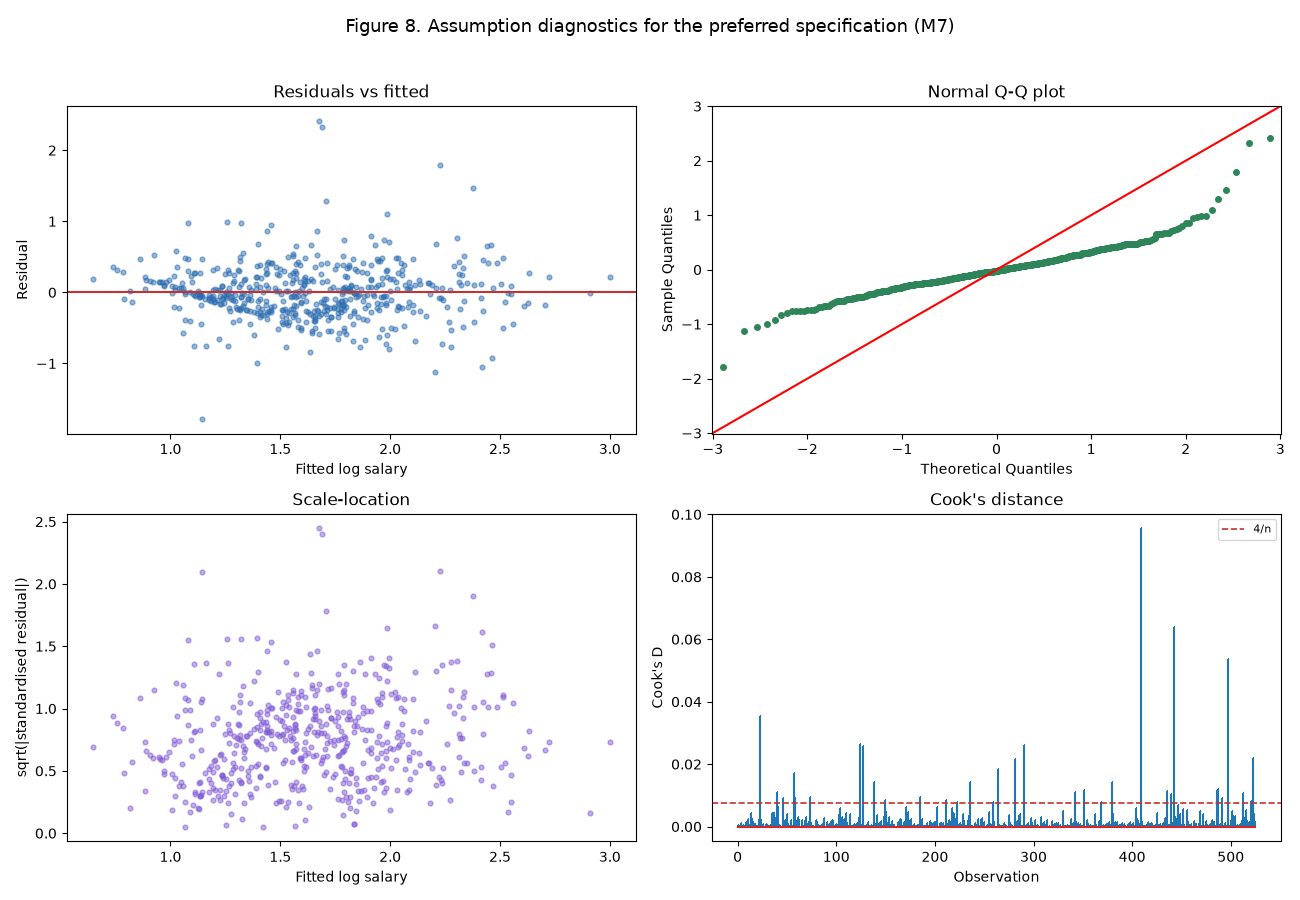

09_marginal_effects.png


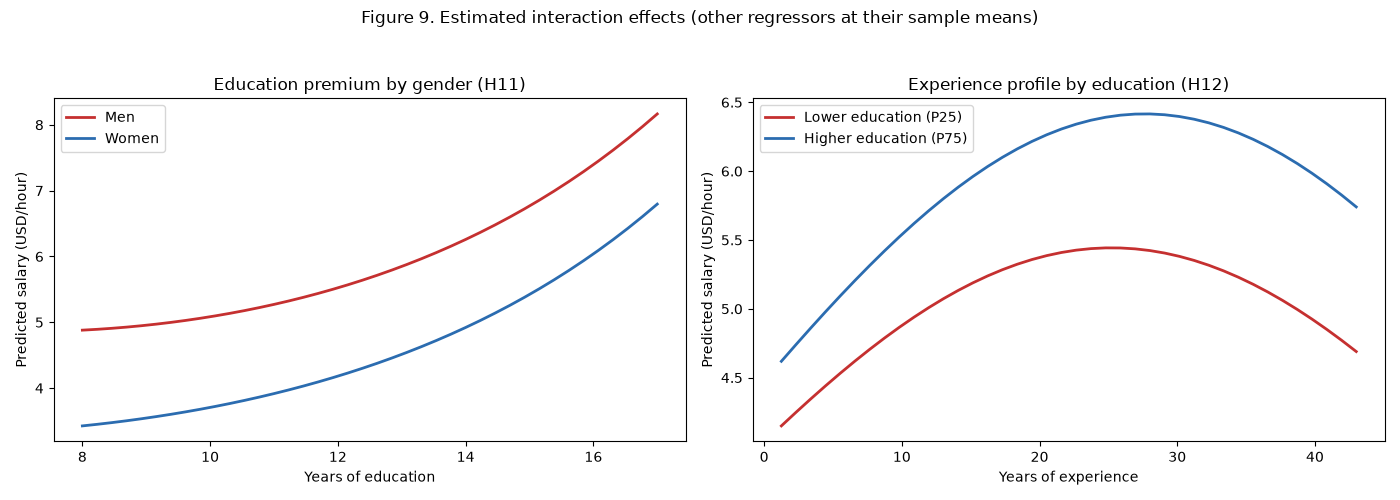

In [8]:
from IPython.display import Image, display
for p in sorted((ROOT / 'report_charts').glob('0[89]*.png')):
    print(p.name)
    display(Image(filename=str(p), width=900))